In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import pandas as pd
import yaml
from scipy.optimize import least_squares


In [2]:
# Relative permeability parameters

parametros = {
    "agua": {"kr0": 0.365, "Sr": 0.36, "expoente": 2.7},
    "gas":  {"kr0": 0.278, "Sr": 0.00, "expoente": 6.89},
    "oleo": {"kr0": 0.574, "Sr": 0.16, "expoente": 3.0},
    # "oleo": {"kr0": 0.574, "Sr": 0.066, "expoente": 3.0},
}

def corey(S, kr0, Sr, expoente, parametros):
    saturacao_movel = 1.0 - sum(p["Sr"] for p in parametros.values())
    if saturacao_movel <= 0:
        raise ValueError("saturacao_movel deve ser positiva.")
    Se = np.clip((np.asarray(S) - Sr) / saturacao_movel, 0.0, 1.0)
    return kr0 * Se**expoente

In [3]:
# Reading inputs

with open("inputs/sample3_inputs.yaml", "r") as f:
    inputs = yaml.safe_load(f)


In [4]:
Sw = np.linspace(parametros["agua"]["Sr"], 1 - parametros["gas"]["Sr"] - parametros["oleo"]["Sr"], 10000, endpoint=True)
Sg = 1 - Sw
So = np.zeros_like(Sw)


In [5]:
mug = inputs['fluids']['mug']
muw = inputs['fluids']['muw']
muo = inputs['fluids']['muo']

krw = corey(Sw, **parametros["agua"], parametros=parametros)
krg = corey(Sg, **parametros["gas"], parametros=parametros)
kro = corey(So, **parametros["oleo"], parametros=parametros)

mobg = krg/mug
mobw = krw/muw
mobo = kro/muo

mobt = mobg + mobw + mobo

fg = mobg/mobt
muApp = 1/mobt
    
baselineFG075 = [1.2114, 1.0609, 1.0362]


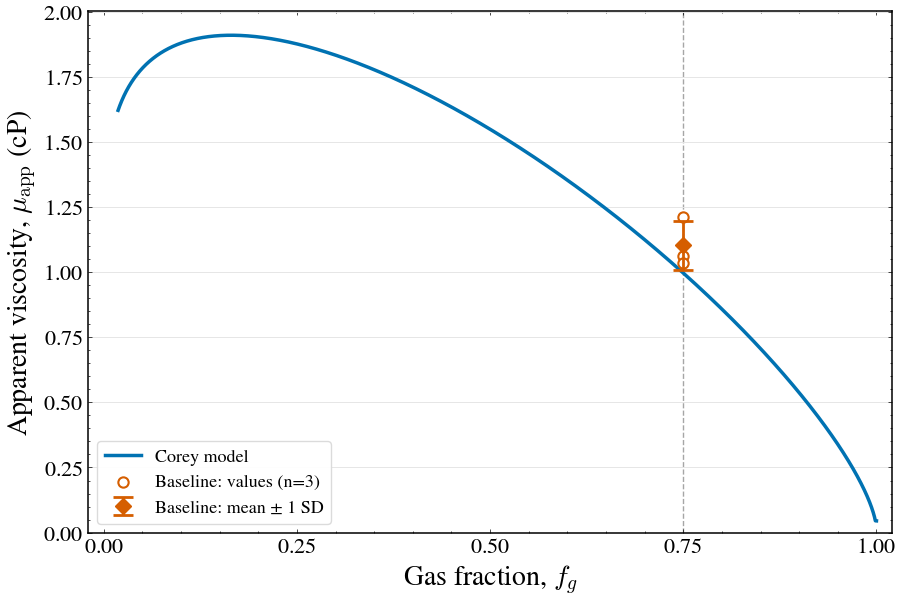

In [6]:
# baselineFG075 is in cP; muApp is calculated in Pa.s.
baseline_values = np.asarray(baselineFG075, dtype=float)
baseline_mean = baseline_values.mean()
baseline_std = baseline_values.std(ddof=1)  # Sample standard deviation.

with plt.style.context(["science", "no-latex"]), plt.rc_context({
    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 13,
    "axes.linewidth": 1.1,
}):
    fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
    ax.plot(fg, muApp * 1e3, color="#0072B2", linewidth=2.5,
            label="Corey model")
    ax.axvline(0.75, color="0.65", linestyle="--", linewidth=1, zorder=0)
    ax.scatter(np.full(baseline_values.shape, 0.75), baseline_values,
               s=55, facecolors="white", edgecolors="#D55E00", linewidths=1.5,
               label=f"Baseline: values (n={baseline_values.size})", zorder=4)
    ax.errorbar(0.75, baseline_mean, yerr=baseline_std,
                fmt="D", color="#D55E00", markersize=8,
                capsize=7, capthick=2, elinewidth=2,
                label="Baseline: mean ± 1 SD", zorder=5)

    ax.set_xlabel(r"Gas fraction, $f_g$")
    ax.set_ylabel(r"Apparent viscosity, $\mu_{\mathrm{app}}$ (cP)")
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", which="major", color="0.9", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.legend(loc="lower left", frameon=True, framealpha=0.95, edgecolor="0.85")
    plt.show()


In [7]:
fg050 = 0.5
id = np.argmin(np.abs(fg - fg050))
print(fg[id], muApp[id])

# Darcy
u = 2.07194251065       # ft./day   # TODO:
# u = 16.5755       # ft./day
u *= 3.52777778e-6      # to m/s

K = inputs['core']['k']
L = inputs['core']['L']
deltaPref = u * muApp[id] * L / (K)
print(deltaPref, "[Pa]") 

0.5001245139445439 0.0015485133682515652
6866.587167520158 [Pa]


In [8]:
# Read oil experiment data from Vieira 2024

with open("inputs/sample3_experimentalData.yaml", "r") as f:
    experiments = yaml.safe_load(f)

oil_observations = pd.DataFrame(
    experiments["oil_observations"]["data"],
    columns=["So", "F2", "FMMOB"]
)
So_exp = oil_observations["So"].to_numpy(dtype=float)
FMMOB_exp = oil_observations["FMMOB"].to_numpy(dtype=float)

In [9]:
# Evaluate experimental quantities

FMref = 1 / (1 + FMMOB_exp)         # Vieira 2024
deltaP_foam = deltaPref / FMref     # Vieira 2024
muApp_exp = K * deltaP_foam / (u * L)

muApp_exp

array([0.02717641, 0.01729689, 0.01170676, 0.00658118])

In [10]:
# de Miranda 2025
def So_func(uwuo, fg, muApp, muo, parametros):
    return np.power( (muo/(parametros['oleo']['kr0']*muApp))*((1-fg)/(1+uwuo)) , 1/parametros['oleo']['expoente']) * (1 - parametros["agua"]["Sr"] - parametros["gas"]["Sr"] - parametros["oleo"]["Sr"]) + parametros["oleo"]["Sr"]

def residuo_uwuo(uwuo, fg, muApp, muo, parametros, So_alvo):
    return np.atleast_1d(So_func(uwuo, fg, muApp, muo, parametros) - So_alvo)

fg = 0.5

uwuo = np.full(So_exp.shape, np.nan)
So_fit = np.full(So_exp.shape, np.nan)
resultados_otimizacao = [None] * So_exp.size
status_ajuste = []
tolerancia_So = 1e-8

for i, muApp in enumerate(muApp_exp):
    So_alvo = So_exp[i]
    # With fg=0.5 and positive viscosities, So_func > Sr_oleo for uwuo >= 0.
    if So_alvo <= parametros["oleo"]["Sr"]:
        status_ajuste.append("Sem raiz física: So_exp <= Sr_oleo")
        continue

    resultado = least_squares(
        residuo_uwuo,
        x0=[0.5],
        # uwuo = u_w/u_o is nonnegative and can exceed 1.
        # With 1 + uwuo, there is no singularity in this domain.
        bounds=(0.0, np.inf),
        args=(fg, muApp, muo, parametros, So_alvo),
        x_scale="jac",
        ftol=1e-14, xtol=1e-14, gtol=1e-14,
        max_nfev=10000,
    )
    resultados_otimizacao[i] = resultado
    uwuo[i] = resultado.x[0]
    So_fit[i] = So_func(uwuo[i], fg, muApp, muo, parametros)
    raiz_ok = resultado.success and abs(So_alvo - So_fit[i]) <= tolerancia_So
    status_ajuste.append("Raiz encontrada" if raiz_ok else "Ajuste sem raiz na tolerância")

ajuste_uwuo = pd.DataFrame({
    "So_exp": So_exp,
    "muApp_exp_Pa_s": muApp_exp,
    "uwuo": uwuo,
    "So_fit": So_fit,
    "erro_abs_So": np.abs(So_exp - So_fit),
    "raiz_encontrada": np.abs(So_exp - So_fit) <= tolerancia_So,
    "status": status_ajuste,
})
ajuste_uwuo


,So_exp,muApp_exp_Pa_s,uwuo,So_fit,erro_abs_So,raiz_encontrada,status
0,0.2191,0.027176,84.861270,0.2191,9.148238e-14,True,Raiz encontrada
1,0.2724,0.017297,18.610324,0.2724,7.438494e-15,True,Raiz encontrada
2,0.3115,0.011707,10.832518,0.3115,9.325873e-14,True,Raiz encontrada
3,0.3541,0.006581,9.008554,0.3541,9.436896e-16,True,Raiz encontrada


In [11]:
# Evaluate velocities

# u is known
ug = fg*u

uwuo = ajuste_uwuo['uwuo']
uwuo

# uw + uo = uliq
uliq = u - ug
uo = uliq / (uwuo + 1)
uw = uwuo * uo

uouw = uo/uw
uouw

0    0.011784
1    0.053734
2    0.092315
3    0.111006
Name: uwuo, dtype: float64

In [12]:
So_func(uwuo, fg, muApp_exp, muo, parametros)

0    0.2191
1    0.2724
2    0.3115
3    0.3541
Name: uwuo, dtype: float64

In [13]:
# Evaluate Sw

def Sw_func(uouw, fg, muApp, muw, parametros):
    return np.power( (muw/(parametros['agua']['kr0']*muApp))*((1-fg)/(1+uouw)) , 1/parametros['agua']['expoente']) * (1 - parametros["agua"]["Sr"] - parametros["gas"]["Sr"] - parametros["oleo"]["Sr"]) + parametros["agua"]["Sr"]

Sw_fit = np.full(muApp_exp.shape, np.nan)

for i, (muApp_i, uouw_i) in enumerate(zip(muApp_exp, uouw)):
    Sw_fit[i] = Sw_func(uouw_i, fg, muApp_i, muw, parametros)

ajuste_uwuo["uouw"] = np.asarray(uouw)
ajuste_uwuo["Sw_fit"] = Sw_fit
Sg_fit = 1 - So_fit - Sw_fit
ajuste_uwuo['Sg_fit'] = Sg_fit

ajuste_uwuo


,So_exp,muApp_exp_Pa_s,uwuo,So_fit,erro_abs_So,raiz_encontrada,status,uouw,Sw_fit,Sg_fit
0,0.2191,0.027176,84.861270,0.2191,9.148238e-14,True,Raiz encontrada,0.011784,0.491048,0.289852
1,0.2724,0.017297,18.610324,0.2724,7.438494e-15,True,Raiz encontrada,0.053734,0.512606,0.214994
2,0.3115,0.011707,10.832518,0.3115,9.325873e-14,True,Raiz encontrada,0.092315,0.534012,0.154488
3,0.3541,0.006581,9.008554,0.3541,9.436896e-16,True,Raiz encontrada,0.111006,0.574038,0.071862


In [14]:
dataset = {
    'So': So_fit,
    'Sw': Sw_fit,
    'Sg': Sg_fit,
    'muApp': muApp_exp,
    'fg': fg*np.ones_like(muApp_exp)
}
dataset = pd.DataFrame(dataset)
dataset.head()


,So,Sw,Sg,muApp,fg
0,0.2191,0.491048,0.289852,0.027176,0.5
1,0.2724,0.512606,0.214994,0.017297,0.5
2,0.3115,0.534012,0.154488,0.011707,0.5
3,0.3541,0.574038,0.071862,0.006581,0.5


In [15]:
columns = ["So", "Sw", "Sg", "muApp", "fg"]

print("oil_observations_preprocessed:")
print(f"  surfactant_concentration_mg_L: 5000")
print(f"  data: # {', '.join(columns)}")

for row in zip(*(dataset[col] for col in columns)):
    print("    - [" + ", ".join(f"{v:.8g}" for v in row) + "]")

oil_observations_preprocessed:
  surfactant_concentration_mg_L: 5000
  data: # So, Sw, Sg, muApp, fg
    - [0.2191, 0.49104843, 0.28985157, 0.02717641, 0.5]
    - [0.2724, 0.51260645, 0.21499355, 0.017296894, 0.5]
    - [0.3115, 0.53401162, 0.15448838, 0.011706761, 0.5]
    - [0.3541, 0.57403805, 0.071861952, 0.0065811818, 0.5]


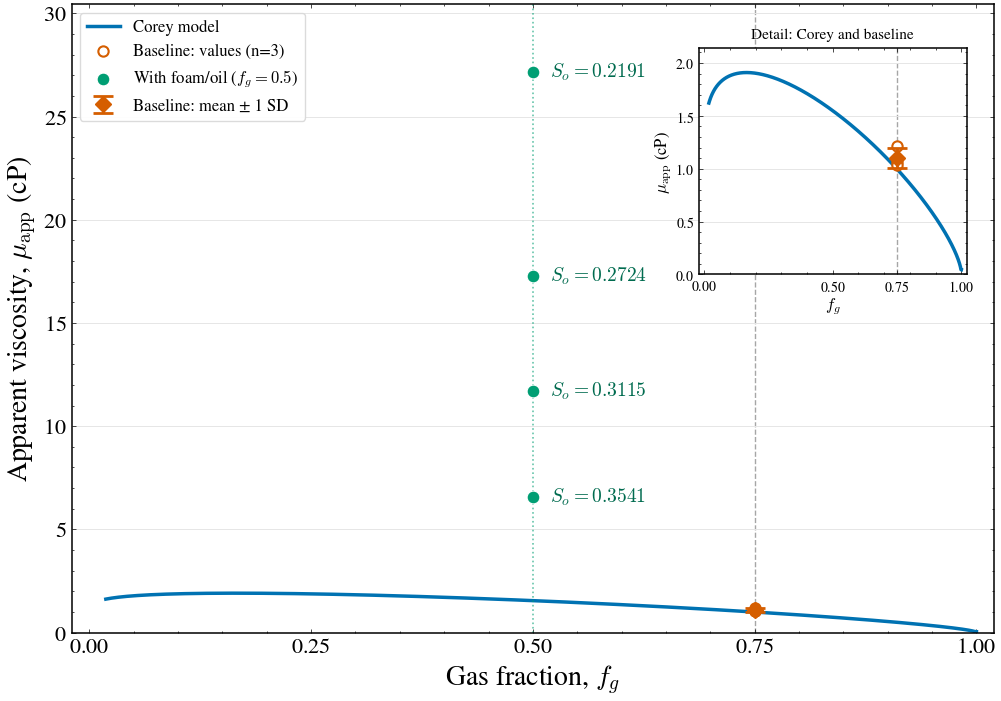

In [16]:
# Final comparison: Corey curve, baseline, and oil data at fg = 0.5.
# Reconstruct the curve because fg and muApp were reused in earlier loops.
fg_corey = mobg / mobt
muApp_corey_cP = 1e3 / mobt
baseline_values = np.asarray(baselineFG075, dtype=float)  # Already in cP.
baseline_mean = baseline_values.mean()
baseline_std = baseline_values.std(ddof=1)

pontos_oleo = pd.DataFrame({
    "fg": np.full(muApp_exp.shape, fg050),
    "muApp_cP": muApp_exp * 1e3,
    "So": So_exp,
}).dropna()

with plt.style.context(["science", "no-latex"]), plt.rc_context({
    "font.size": 17,
    "axes.labelsize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 12,
    "axes.linewidth": 1.1,
}):
    fig_final, ax_final = plt.subplots(figsize=(10, 7), constrained_layout=True)
    ax_zoom = ax_final.inset_axes([0.68, 0.57, 0.29, 0.36])

    for eixo in (ax_final, ax_zoom):
        eixo.plot(fg_corey, muApp_corey_cP, color="#0072B2", linewidth=2.5,
                  label="Corey model")
        eixo.axvline(0.75, color="0.65", linestyle="--", linewidth=1, zorder=0)
        eixo.scatter(np.full(baseline_values.shape, 0.75), baseline_values,
                     s=55, facecolors="white", edgecolors="#D55E00", linewidths=1.5,
                     label=f"Baseline: values (n={baseline_values.size})", zorder=4)
        eixo.errorbar(0.75, baseline_mean, yerr=baseline_std,
                      fmt="D", color="#D55E00", markersize=8,
                      capsize=7, capthick=2, elinewidth=2,
                      label="Baseline: mean ± 1 SD", zorder=5)
        eixo.set_xlim(-0.02, 1.02)
        eixo.grid(axis="y", which="major", color="0.9", linewidth=0.7)
        eixo.set_axisbelow(True)

    ax_final.axvline(fg050, color="#009E73", linestyle=":", linewidth=1.2, alpha=0.6)
    ax_final.scatter(pontos_oleo["fg"], pontos_oleo["muApp_cP"],
                     s=85, color="#009E73", edgecolors="white", linewidths=0.8,
                     label=r"With foam/oil ($f_g = 0.5$)", zorder=6)
    for ponto in pontos_oleo.itertuples(index=False):
        ax_final.annotate(
            rf"$S_o = {ponto.So:.4f}$", (ponto.fg, ponto.muApp_cP),
            xytext=(12, 0), textcoords="offset points", va="center",
            fontsize=14, color="#006B4F",
        )

    ax_final.set_xlabel(r"Gas fraction, $f_g$")
    ax_final.set_ylabel(r"Apparent viscosity, $\mu_{\mathrm{app}}$ (cP)")
    ax_final.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
    ax_final.set_ylim(0, 1.12 * max(muApp_corey_cP.max(),
                                  pontos_oleo["muApp_cP"].max(),
                                  baseline_values.max(), baseline_mean + baseline_std))
    ax_final.legend(loc="upper left", frameon=True, framealpha=0.95, edgecolor="0.85")

    ax_zoom.set_ylim(0, 1.12 * max(muApp_corey_cP.max(), baseline_values.max(),
                                 baseline_mean + baseline_std))
    ax_zoom.set_xticks([0.0, 0.5, 0.75, 1.0])
    ax_zoom.tick_params(axis="both", which="major", labelsize=10)
    ax_zoom.set_xlabel(r"$f_g$", fontsize=12, labelpad=1)
    ax_zoom.set_ylabel(r"$\mu_{\mathrm{app}}$ (cP)", fontsize=12, labelpad=1)
    ax_zoom.set_title("Detail: Corey and baseline", fontsize=11, pad=7)
    plt.show()


In [17]:
dataset.head()

,So,Sw,Sg,muApp,fg
0,0.2191,0.491048,0.289852,0.027176,0.5
1,0.2724,0.512606,0.214994,0.017297,0.5
2,0.3115,0.534012,0.154488,0.011707,0.5
3,0.3541,0.574038,0.071862,0.006581,0.5
